In [118]:
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeClassifier
import warnings
warnings.filterwarnings('ignore')

In [119]:
df=pd.read_csv("WineQT.csv")
df

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,0
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5,1
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5,2
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6,3
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1138,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6,1592
1139,6.8,0.620,0.08,1.9,0.068,28.0,38.0,0.99651,3.42,0.82,9.5,6,1593
1140,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5,1594
1141,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6,1595


In [65]:
df.shape

(1143, 13)

In [66]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
count,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000
mean,8.311111,0.531339,0.268364,2.532152,0.086933,15.615486,45.914698,0.996730,3.311015,0.657708,10.442111,5.657043,804.969379
std,1.747595,0.179633,0.196686,1.355917,0.047267,10.250486,32.782130,0.001925,0.156664,0.170399,1.082196,0.805824,463.997116
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000,0.000000
25%,7.100000,0.392500,0.090000,1.900000,0.070000,7.000000,21.000000,0.995570,3.205000,0.550000,9.500000,5.000000,411.000000
50%,7.900000,0.520000,0.250000,2.200000,0.079000,13.000000,37.000000,0.996680,3.310000,0.620000,10.200000,6.000000,794.000000
75%,9.100000,0.640000,0.420000,2.600000,0.090000,21.000000,61.000000,0.997845,3.400000,0.730000,11.100000,6.000000,1209.500000
max,15.900000,1.580000,1.000000,15.500000,0.611000,68.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000,1597.000000


In [67]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


In [68]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [69]:
df.dtypes

fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
Id                        int64
dtype: object

In [70]:
df.isnull()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1138,False,False,False,False,False,False,False,False,False,False,False,False,False
1139,False,False,False,False,False,False,False,False,False,False,False,False,False
1140,False,False,False,False,False,False,False,False,False,False,False,False,False
1141,False,False,False,False,False,False,False,False,False,False,False,False,False


In [71]:
df.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Id                      0
dtype: int64

In [72]:
from sklearn.model_selection import train_test_split

In [73]:
X = df.drop(columns=['quality', 'Id'])
y = df['quality']

In [74]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [75]:
model=DecisionTreeClassifier(criterion="gini",max_depth=5,min_samples_split=2,min_samples_leaf=1,random_state=42)

In [76]:
model.fit(X_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [77]:
y_pred=model.predict(X_test)

In [78]:
acc=accuracy_score(y_test,y_pred)
print(acc)

0.611353711790393


In [79]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

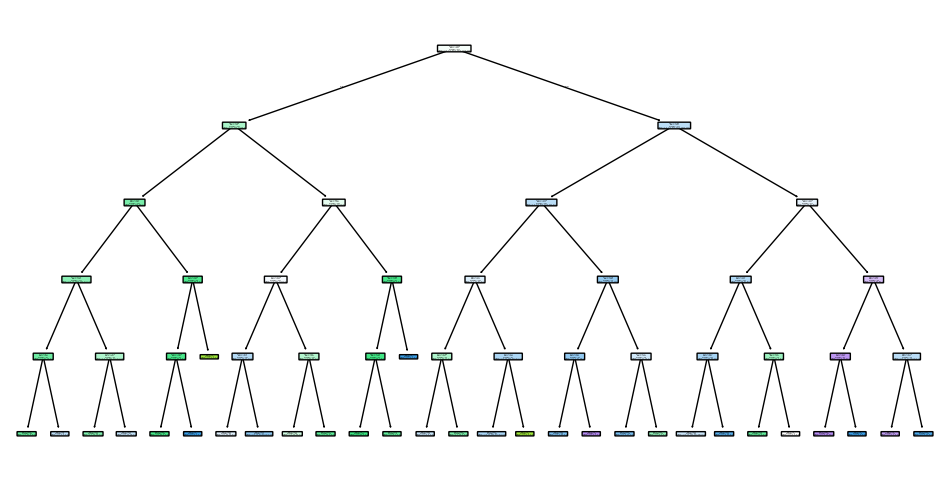

In [80]:
plt.figure(figsize=(12,6))
plot_tree(model,filled=True,rounded=True)
plt.show()

In [81]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from  sklearn.linear_model import LogisticRegression

In [82]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


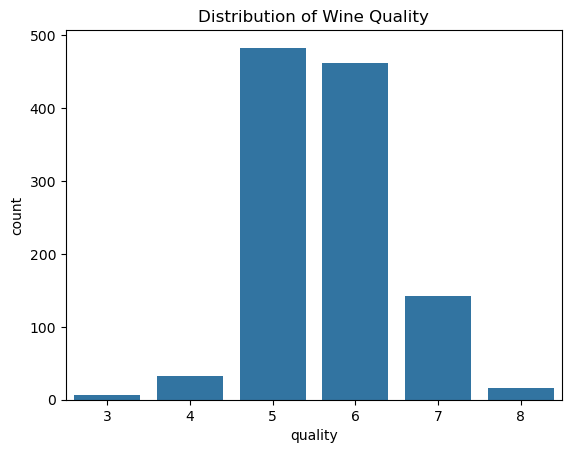

In [83]:
sns.countplot(data=df, x='quality')
plt.title('Distribution of Wine Quality')
plt.show()


In [84]:
df = pd.get_dummies(df, drop_first= True)
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [85]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [86]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)

In [87]:
acc_knn= accuracy_score(y_test,y_pred_knn)
print(acc_knn)

0.5589519650655022


In [88]:
cn_knn= confusion_matrix(y_test,y_pred_knn)
print(cn_knn)

[[ 0  4  2  0  0]
 [ 2 66 28  0  0]
 [ 1 34 55  9  0]
 [ 0  5 14  7  0]
 [ 0  0  2  0  0]]


In [89]:
print(classification_report(y_test, y_pred_knn))

              precision    recall  f1-score   support

           4       0.00      0.00      0.00         6
           5       0.61      0.69      0.64        96
           6       0.54      0.56      0.55        99
           7       0.44      0.27      0.33        26
           8       0.00      0.00      0.00         2

    accuracy                           0.56       229
   macro avg       0.32      0.30      0.31       229
weighted avg       0.54      0.56      0.55       229



In [90]:
nb = GaussianNB()
nb.fit(X_train,y_train)
y_pred_nb= nb.predict(X_test)

In [91]:
acc_nb= accuracy_score(y_test,y_pred_nb)
print(acc_nb)

0.5851528384279476


In [92]:
cn_nb= confusion_matrix(y_test,y_pred_nb)
print(cn_nb)

[[ 0  0  0  0  0  0]
 [ 0  0  4  2  0  0]
 [ 2  2 51 40  1  0]
 [ 0  4 13 68 12  2]
 [ 0  0  2  8 15  1]
 [ 0  0  0  0  2  0]]


In [93]:
print(classification_report(y_test, y_pred_nb))

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         0
           4       0.00      0.00      0.00         6
           5       0.73      0.53      0.61        96
           6       0.58      0.69      0.63        99
           7       0.50      0.58      0.54        26
           8       0.00      0.00      0.00         2

    accuracy                           0.59       229
   macro avg       0.30      0.30      0.30       229
weighted avg       0.61      0.59      0.59       229



In [94]:
from sklearn.svm import SVC

In [95]:
svc = SVC()

In [96]:
svc.fit(X_train,y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [97]:
y_pred_svc = svc.predict(X_test)

In [98]:
acc_svc= accuracy_score(y_test,y_pred_nb)
print(acc_svc)

0.5851528384279476


In [99]:
cm_svc= confusion_matrix(y_test,y_pred_nb)
print(cm_svc)

[[ 0  0  0  0  0  0]
 [ 0  0  4  2  0  0]
 [ 2  2 51 40  1  0]
 [ 0  4 13 68 12  2]
 [ 0  0  2  8 15  1]
 [ 0  0  0  0  2  0]]


In [100]:
print(classification_report(y_test, y_pred_svc))

              precision    recall  f1-score   support

           4       0.00      0.00      0.00         6
           5       0.70      0.74      0.72        96
           6       0.59      0.69      0.64        99
           7       0.54      0.27      0.36        26
           8       0.00      0.00      0.00         2

    accuracy                           0.64       229
   macro avg       0.37      0.34      0.34       229
weighted avg       0.61      0.64      0.62       229



In [101]:
from sklearn.linear_model import LogisticRegression

In [102]:
lr = LogisticRegression(max_iter=1000)

In [103]:
lr.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [104]:
y_pred_lr = lr.predict(X_test)

In [105]:
acc_lr = accuracy_score(y_test, y_pred_lr)
print(acc_lr)

0.62882096069869


In [106]:
cm_lr = confusion_matrix(y_test, y_pred_lr)
print(cm_lr)

[[ 0  3  3  0  0]
 [ 1 70 23  2  0]
 [ 0 28 63  8  0]
 [ 0  2 13 11  0]
 [ 0  0  0  2  0]]


In [107]:
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           4       0.00      0.00      0.00         6
           5       0.68      0.73      0.70        96
           6       0.62      0.64      0.63        99
           7       0.48      0.42      0.45        26
           8       0.00      0.00      0.00         2

    accuracy                           0.63       229
   macro avg       0.36      0.36      0.36       229
weighted avg       0.61      0.63      0.62       229



In [108]:
from sklearn.metrics import precision_score, recall_score, f1_score

In [110]:
comparision = pd.DataFrame({
    'Model': ['KNN', 'NB', 'LR', 'SVM'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_knn), 
        accuracy_score(y_test, y_pred_nb), 
        accuracy_score(y_test, y_pred_lr), 
        accuracy_score(y_test, y_pred_svc)
    ],
    'Precision': [
        precision_score(y_test, y_pred_knn, average='weighted'), 
        precision_score(y_test, y_pred_nb, average='weighted'), 
        precision_score(y_test, y_pred_lr, average='weighted'), 
        precision_score(y_test, y_pred_svc, average='weighted')
    ],
    'Recall': [
        recall_score(y_test, y_pred_knn, average='weighted'), 
        recall_score(y_test, y_pred_nb, average='weighted'), 
        recall_score(y_test, y_pred_lr, average='weighted'), 
        recall_score(y_test, y_pred_svc, average='weighted')
    ],
    'F1 Score': [
        f1_score(y_test, y_pred_knn, average='weighted'), 
        f1_score(y_test, y_pred_nb, average='weighted'), 
        f1_score(y_test, y_pred_lr, average='weighted'), 
        f1_score(y_test, y_pred_svc, average='weighted')
    ]
})

comparision

,Model,Accuracy,Precision,Recall,F1 Score
0,KNN,0.558952,0.538927,0.558952,0.545552
1,NB,0.585153,0.611326,0.585153,0.589356
2,LR,0.628821,0.606221,0.628821,0.616903
3,SVM,0.637555,0.611460,0.637555,0.617673


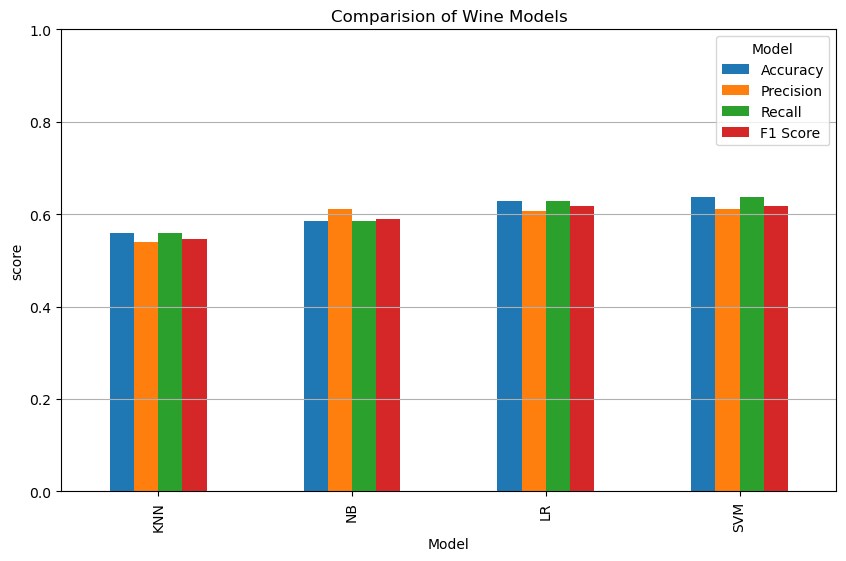

In [112]:
comparision.set_index("Model").plot(kind='bar', figsize=(10,6))

plt.title("Comparision of Wine Models")
plt.ylabel("score")
plt.ylim(0,1)
plt.legend(title = "Model")
plt.grid(axis= 'y')
plt.show()

In [113]:
import joblib

In [114]:
joblib.dump(svc, "best_model.pkl")

['best_model.pkl']

In [115]:
joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']

In [116]:
joblib.dump(X.columns.tolist(), "feature_columns.pkl")

['feature_columns.pkl']

In [117]:
import os
os.listdir()

['.ipynb_checkpoints',
 'best_model.pkl',
 'feature_columns.pkl',
 'scaler.pkl',
 'Untitled.ipynb',
 'WineQT.csv',
 'WineQT.ipynb']

In [122]:
import joblib

# Use the correct variable name 'svc'
joblib.dump(svc, 'wine_model.pkl')

['wine_model.pkl']